# Customer Churn Prediction (Telecom)

**Goal:** predict which customers are likely to stop using the service, understand *why*, and turn that into a retention strategy.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 20 features).
**Models:** Logistic Regression, Random Forest, XGBoost.
**Metrics:** Accuracy, Precision, Recall, F1, ROC-AUC (recall on churners is the priority).

**Contents**
1. Setup and data loading
2. Exploratory data analysis
3. Preprocessing
4. Modelling
5. Evaluation
6. Threshold tuning (cost-based)
7. Explainability with SHAP
8. Business recommendations
9. Save the model

## 1. Setup and data loading

In [1]:
import warnings, os, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from xgboost import XGBClassifier
import shap

SEED = 42
os.makedirs("images", exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
print("\nDuplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Data cleaning
`TotalCharges` is stored as text because 11 rows contain a blank string. Those are brand-new customers with `tenure = 0`, so `TotalCharges` is legitimately 0.

In [3]:
print(df[df["TotalCharges"].str.strip() == ""][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns="customerID")
print("\nMissing values left:", df.isna().sum().sum())

      tenure  MonthlyCharges TotalCharges Churn
488        0           52.55                 No
753        0           20.25                 No
936        0           80.85                 No
1082       0           25.75                 No
1340       0           56.05                 No
3331       0           19.85                 No
3826       0           25.35                 No
4380       0           20.00                 No
5218       0           19.70                 No
6670       0           73.35                 No
6754       0           61.90                 No

Missing values left: 0


## 2. Exploratory data analysis

Overall churn rate: 26.5%  ->  the classes are imbalanced (about 3 stayers per churner)


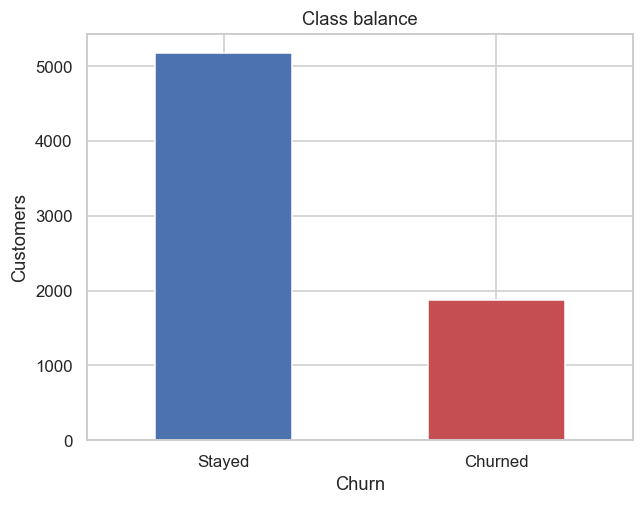

In [4]:
rate = df["Churn"].mean()
print(f"Overall churn rate: {rate:.1%}  ->  the classes are imbalanced (about 3 stayers per churner)")
ax = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Class balance"); ax.set_ylabel("Customers")
plt.savefig("images/01_class_balance.png", bbox_inches="tight"); plt.show()

### 2.1 Churn rate by categorical feature

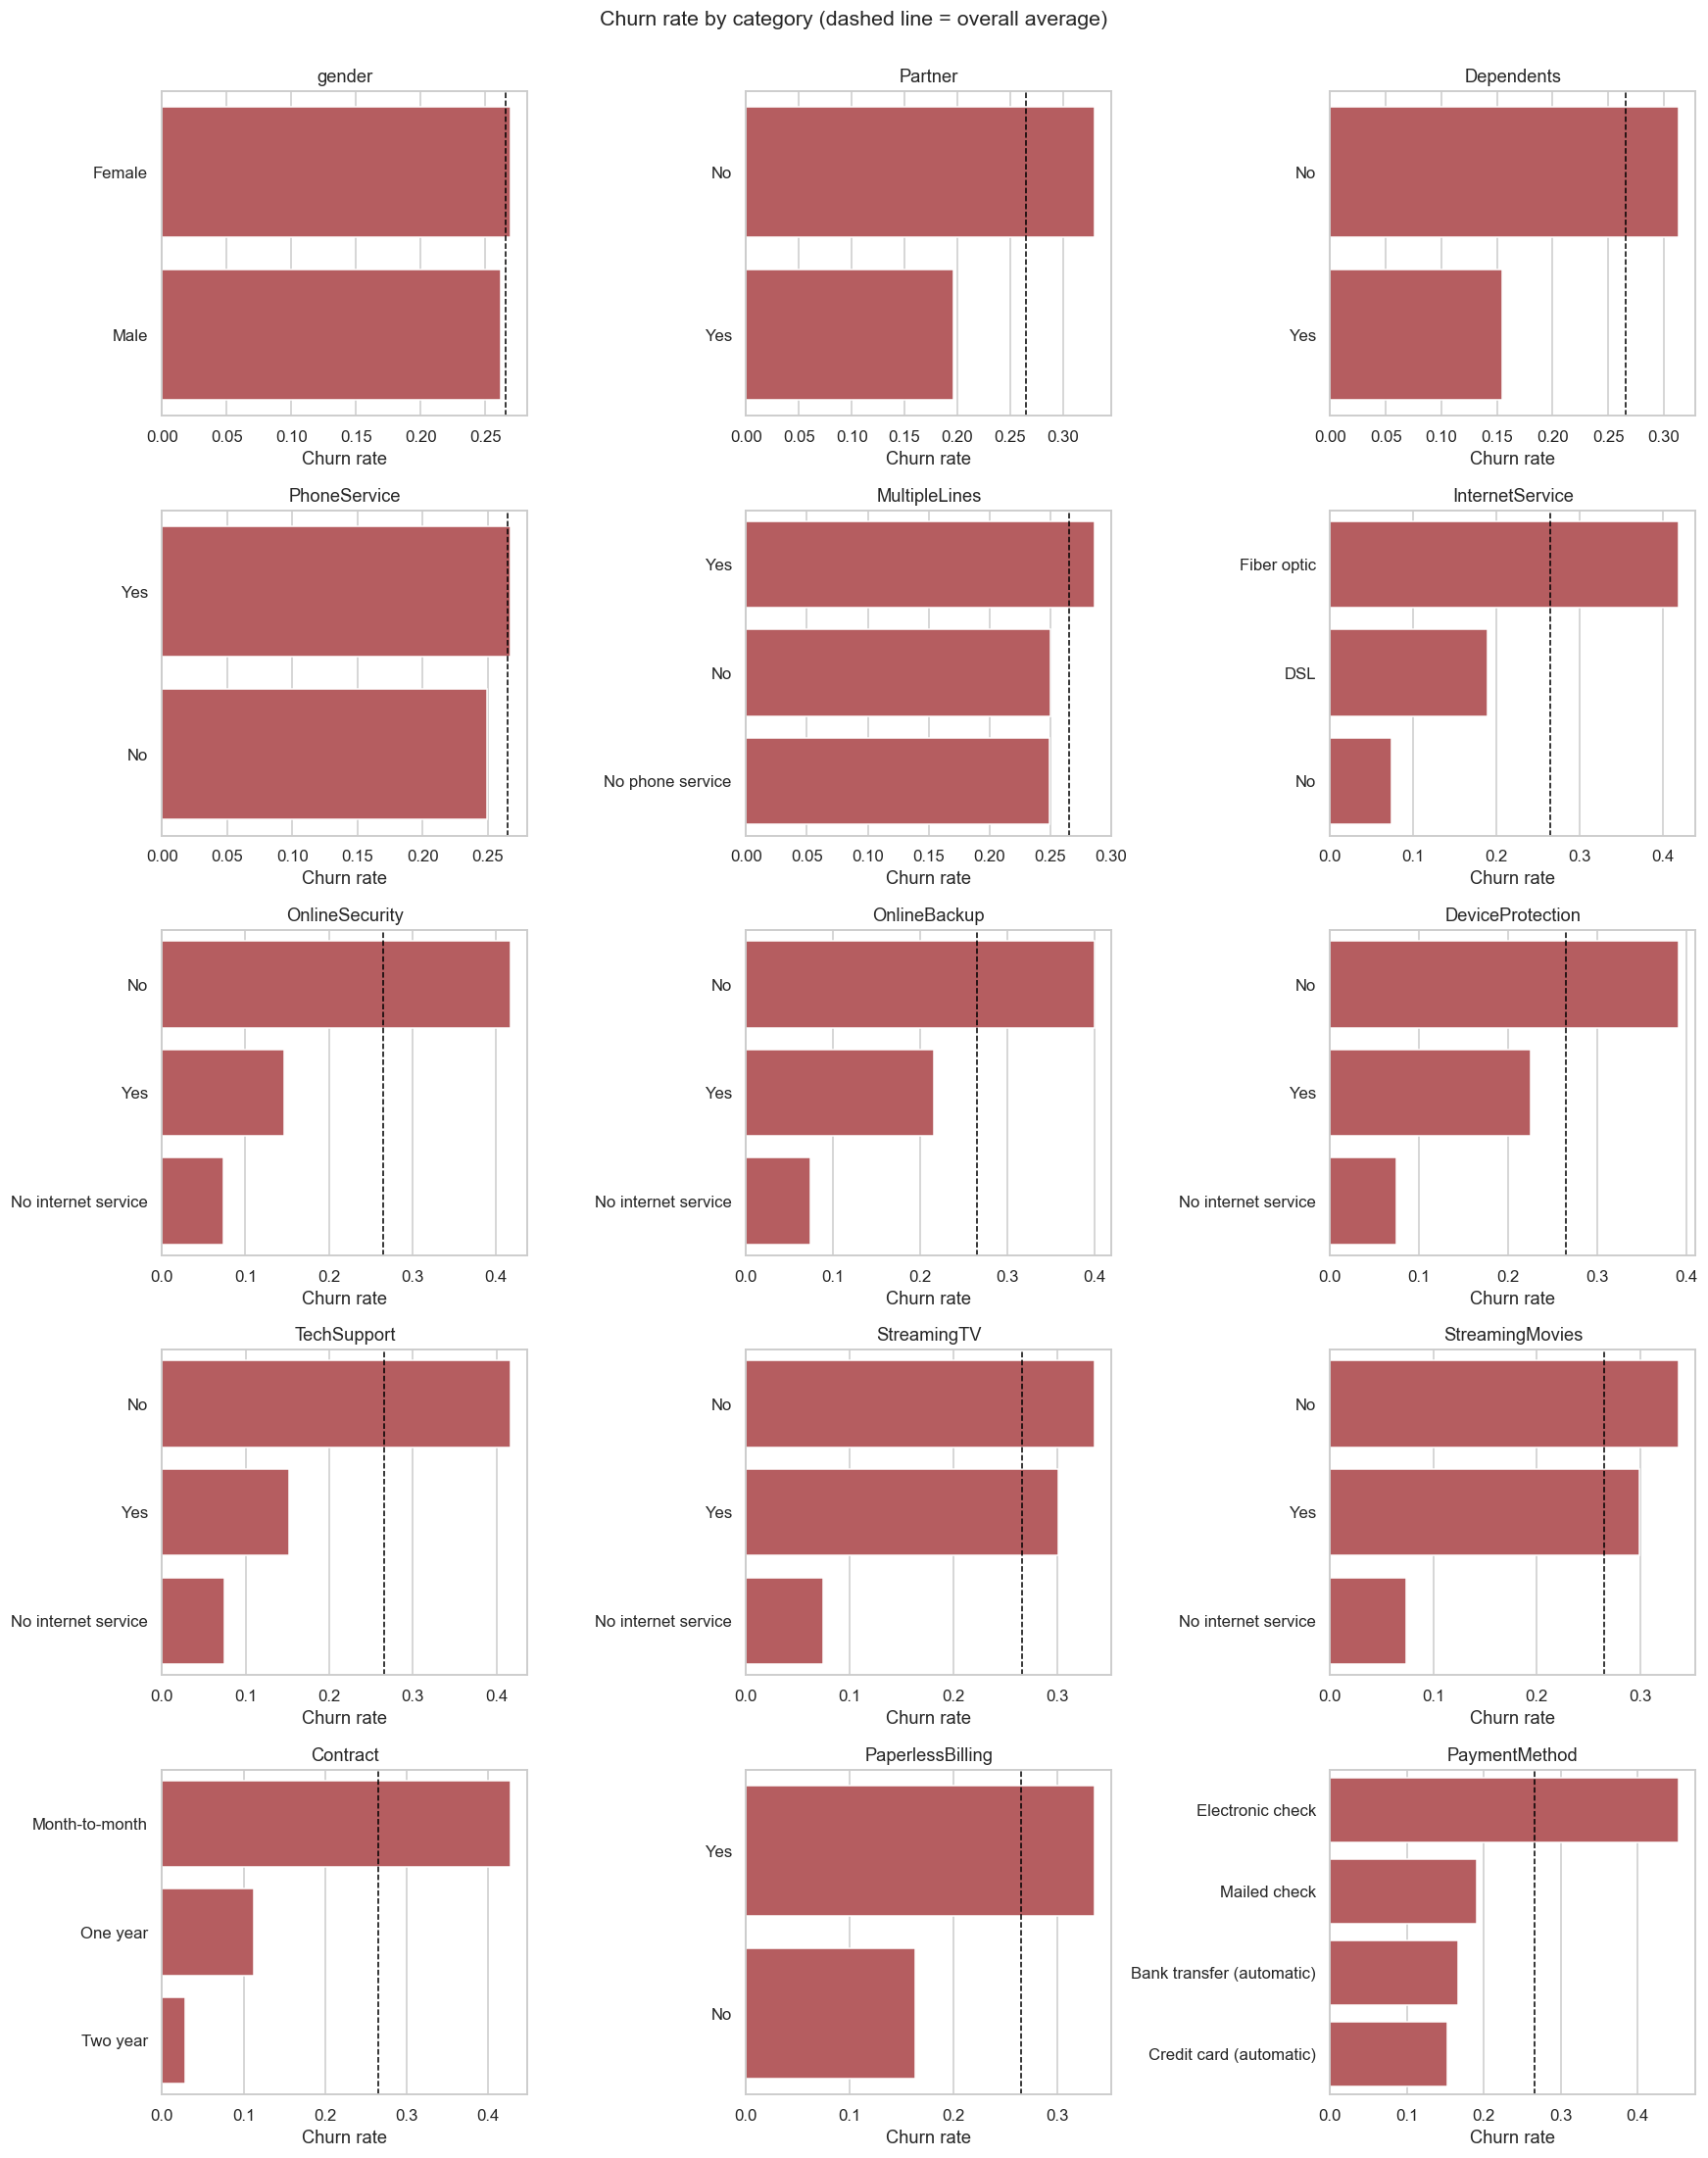

In [5]:
cat_cols = df.select_dtypes("object").columns.tolist()
fig, axes = plt.subplots(5, 3, figsize=(16, 20))
for ax, col in zip(axes.ravel(), cat_cols):
    r = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=r.values, y=r.index, ax=ax, color="#C44E52")
    ax.axvline(rate, color="black", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("Churn rate"); ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]: ax.axis("off")
plt.suptitle("Churn rate by category (dashed line = overall average)", y=1.0, fontsize=14)
plt.tight_layout(); plt.savefig("images/02_churn_by_category.png", bbox_inches="tight"); plt.show()

### 2.2 Numeric features and tenure

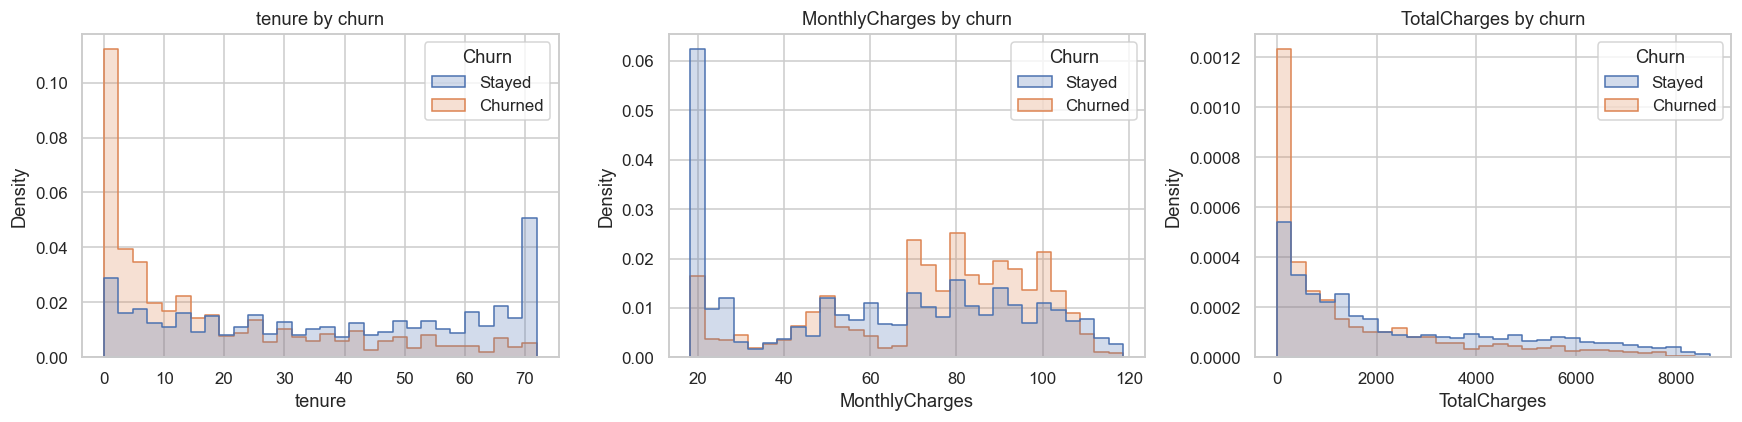

              churn_rate  count
tenure_group                   
0-6                0.529   1481
7-12               0.359    705
13-24              0.287   1024
25-48              0.204   1594
49-72              0.095   2239


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue=df["Churn"].map({0: "Stayed", 1: "Churned"}),
                 bins=30, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout(); plt.savefig("images/03_numeric_distributions.png", bbox_inches="tight"); plt.show()

df["tenure_group"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
print(df.groupby("tenure_group")["Churn"].agg(["mean", "count"]).rename(columns={"mean": "churn_rate"}).round(3))

### 2.3 Contract x tenure, and contract x internet service

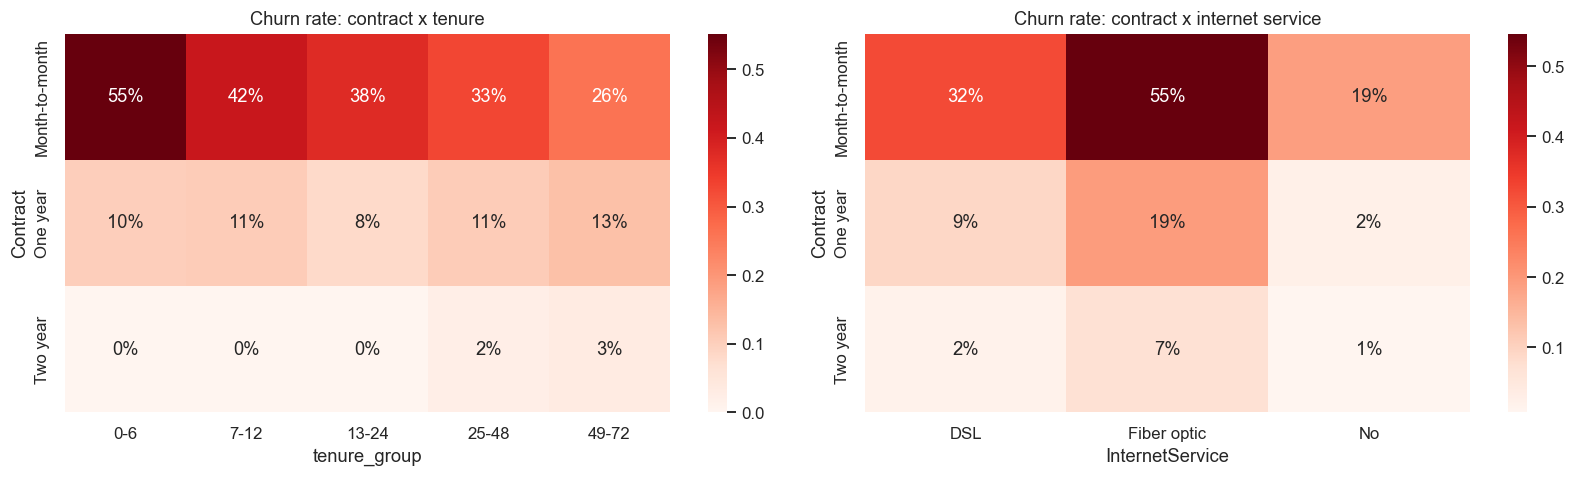

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(df.pivot_table(index="Contract", columns="tenure_group", values="Churn", aggfunc="mean"),
            annot=True, fmt=".0%", cmap="Reds", ax=axes[0]); axes[0].set_title("Churn rate: contract x tenure")
sns.heatmap(df.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean"),
            annot=True, fmt=".0%", cmap="Reds", ax=axes[1]); axes[1].set_title("Churn rate: contract x internet service")
plt.tight_layout(); plt.savefig("images/04_segment_heatmaps.png", bbox_inches="tight"); plt.show()

### 2.4 Correlation with churn

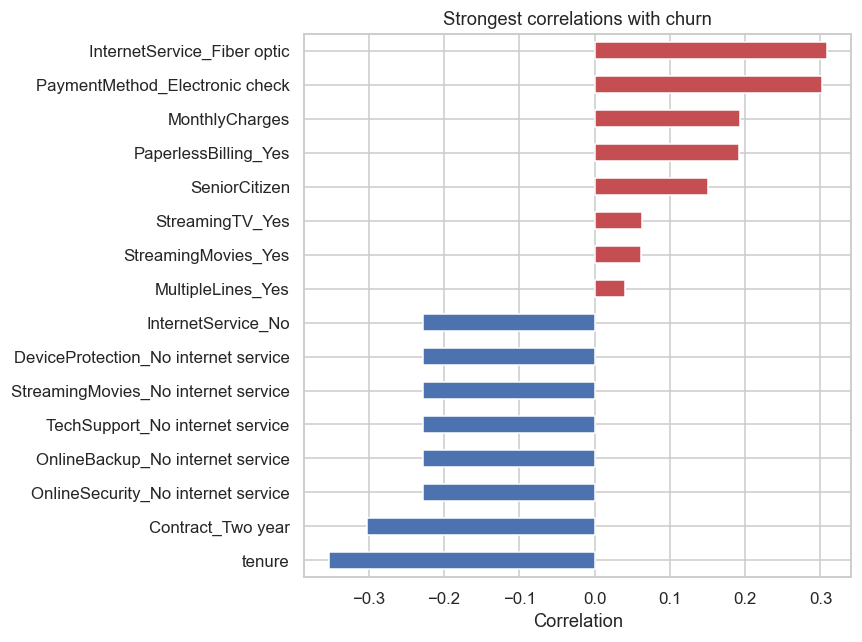

In [8]:
tmp = pd.get_dummies(df.drop(columns="tenure_group"), drop_first=True).astype(float)
corr = tmp.corr()["Churn"].drop("Churn").sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])
plt.figure(figsize=(8, 6))
top.plot.barh(color=["#4C72B0" if v < 0 else "#C44E52" for v in top])
plt.title("Strongest correlations with churn"); plt.xlabel("Correlation")
plt.tight_layout(); plt.savefig("images/05_correlations.png", bbox_inches="tight"); plt.show()

### EDA findings
- **Contract is the strongest signal:** month-to-month customers churn at several times the rate of one- and two-year customers.
- **Early tenure is the danger zone:** churn is highest in the first year and falls steadily after that.
- **Fiber optic customers churn more** and pay more, which suggests a price or service quality problem.
- **Protective add-ons:** customers with Online Security or Tech Support churn far less.
- **Payment method:** electronic check users churn noticeably more than customers on automatic payments.
- Gender and phone service barely move the needle.

**Highest-risk segment:** new, month-to-month, fiber optic customers paying by electronic check with no tech support.

## 3. Preprocessing

In [9]:
df = df.drop(columns="tenure_group")
X, y = df.drop(columns="Churn"), df["Churn"]
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, f"churn {y_train.mean():.1%}  |  Test:", X_test.shape, f"churn {y_test.mean():.1%}")

def make_prep(scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
    ])

Train: (5634, 19) churn 26.5%  |  Test: (1409, 19) churn 26.5%


Preprocessing sits **inside** a `Pipeline`, so scalers and encoders are fitted on training folds only. That prevents data leakage, including during cross-validation.

## 4. Modelling

In [10]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
models = {
    "Logistic Regression": Pipeline([("prep", make_prep(True)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", make_prep(False)),
        ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=5, max_depth=12,
                                       class_weight="balanced", n_jobs=-1, random_state=SEED))]),
    "XGBoost": Pipeline([("prep", make_prep(False)),
        ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                              colsample_bytree=0.8, scale_pos_weight=neg / pos,
                              eval_metric="logloss", random_state=SEED, n_jobs=-1))]),
}
for name, m in models.items():
    m.fit(X_train, y_train); print("fitted", name)

fitted Logistic Regression
fitted Random Forest
fitted XGBoost


### Hyperparameter tuning for XGBoost
Randomized search, optimising ROC-AUC with stratified 5-fold CV.

In [11]:
param_dist = {
    "clf__n_estimators": [150, 250, 400, 600],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "clf__max_depth": [2, 3, 4, 5],
    "clf__min_child_weight": [1, 3, 5, 10],
    "clf__subsample": [0.7, 0.85, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__reg_lambda": [1, 3, 10],
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
search = RandomizedSearchCV(models["XGBoost"], param_dist, n_iter=25, scoring="roc_auc", cv=cv,
                            random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print(search.best_params_)
models["XGBoost (tuned)"] = search.best_estimator_

Best CV ROC-AUC: 0.8502
{'clf__subsample': 0.85, 'clf__reg_lambda': 3, 'clf__n_estimators': 250, 'clf__min_child_weight': 3, 'clf__max_depth': 3, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.6}


## 5. Evaluation

In [12]:
def evaluate(name, model, thr=0.5):
    p = model.predict_proba(X_test)[:, 1]; pred = (p >= thr).astype(int)
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p)}

baseline_acc = 1 - y_test.mean()
results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model").round(3)
print(f"Majority-class baseline accuracy: {baseline_acc:.3f}  (so accuracy alone is misleading)\n")
results

Majority-class baseline accuracy: 0.735  (so accuracy alone is misleading)



,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.737,0.503,0.783,0.613,0.842
Random Forest,0.759,0.531,0.775,0.630,0.841
XGBoost,0.750,0.519,0.794,0.628,0.843
XGBoost (tuned),0.745,0.513,0.799,0.625,0.848


In [13]:
rows = []
for n, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    r = cross_val_score(m, X_train, y_train, cv=cv, scoring="recall", n_jobs=-1)
    rows.append({"Model": n, "CV ROC-AUC": f"{s.mean():.3f} ± {s.std():.3f}", "CV Recall": f"{r.mean():.3f} ± {r.std():.3f}"})
pd.DataFrame(rows).set_index("Model")

,CV ROC-AUC,CV Recall
Model,,
Logistic Regression,0.846 ± 0.012,0.801 ± 0.037
Random Forest,0.846 ± 0.009,0.769 ± 0.034
XGBoost,0.846 ± 0.011,0.797 ± 0.028
XGBoost (tuned),0.850 ± 0.011,0.807 ± 0.026


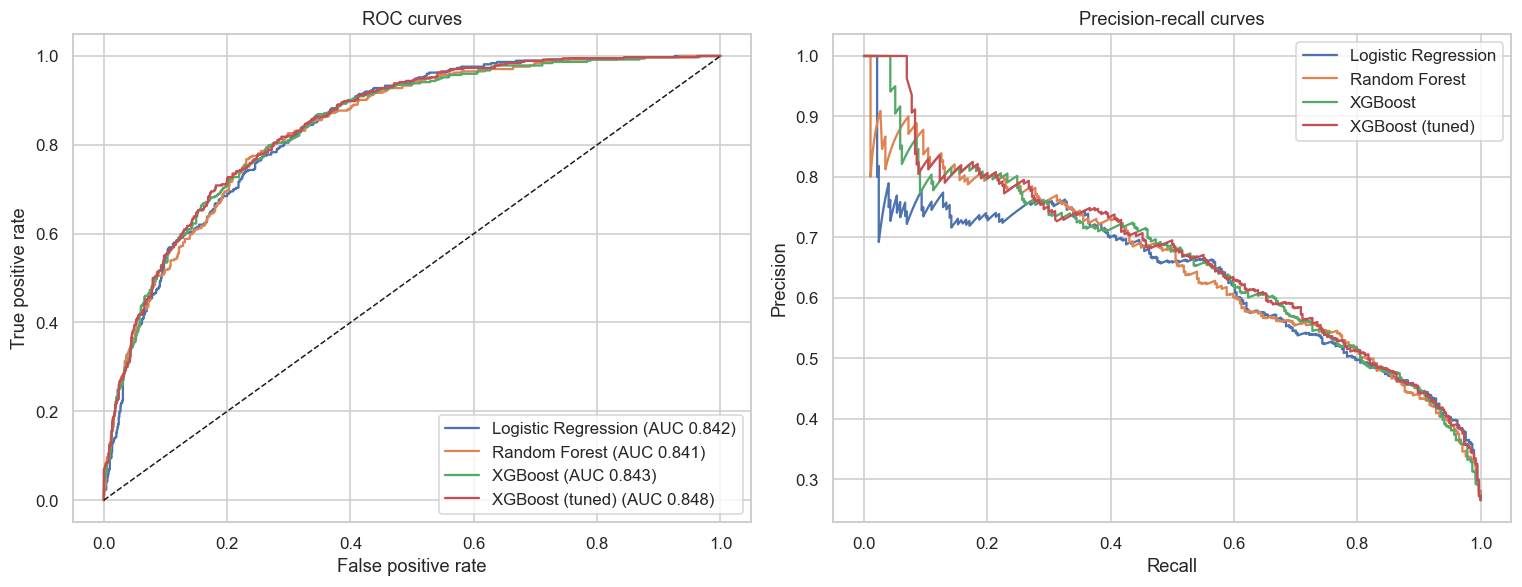

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for n, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=n)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curves"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend()
axes[1].set_title("Precision-recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/06_roc_pr_curves.png", bbox_inches="tight"); plt.show()

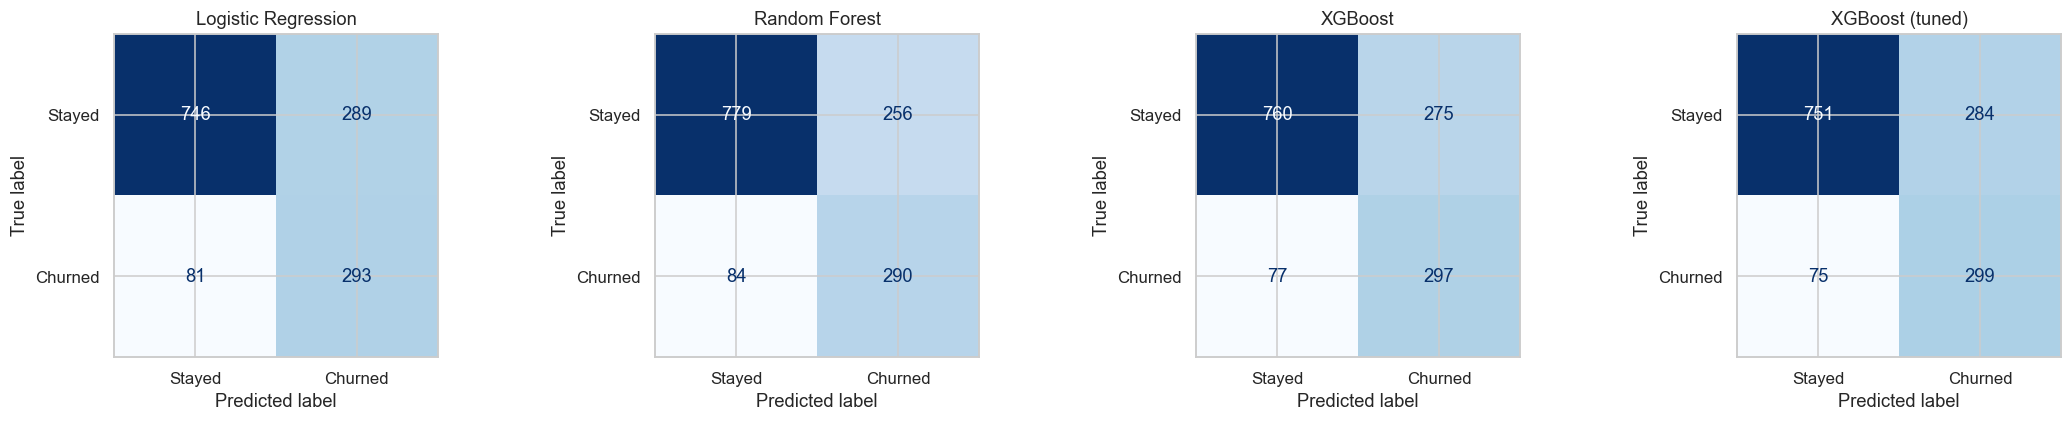

In [15]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
for ax, (n, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Stayed", "Churned"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.savefig("images/07_confusion_matrices.png", bbox_inches="tight"); plt.show()

## 6. Threshold tuning (cost-based)
The default 0.5 cutoff treats both errors equally, but they aren't equal for the business. Assumptions (edit them to match your case):
- Missing a churner (false negative) costs the **customer lifetime value**: assume **500**.
- Contacting someone who wouldn't have left (false positive) costs a **retention offer**: assume **50**.

Model: XGBoost (tuned)
Cost-optimal threshold: 0.17  (cost 34,950 vs 51,700 at 0.50, saving 16,750)


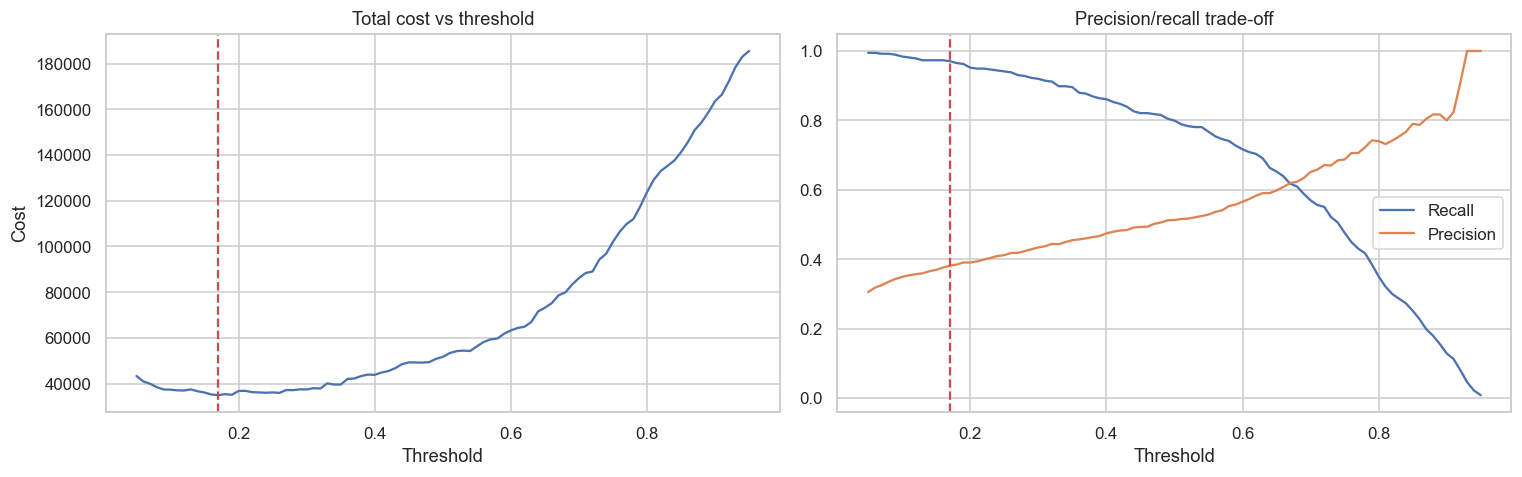

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost (tuned) @0.50,0.745,0.513,0.799,0.625,0.848
XGBoost (tuned) @0.17,0.574,0.381,0.971,0.548,0.848


In [16]:
COST_FN, COST_FP = 500, 50
best_name = results["ROC-AUC"].idxmax(); best = models[best_name]
p = best.predict_proba(X_test)[:, 1]
thrs = np.linspace(0.05, 0.95, 91)
costs, recalls, precs = [], [], []
for t in thrs:
    pred = (p >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    costs.append(fn * COST_FN + fp * COST_FP); recalls.append(tp / (tp + fn)); precs.append(tp / max(tp + fp, 1))
best_t = thrs[int(np.argmin(costs))]
default_cost = costs[int(np.argmin(abs(thrs - 0.5)))]
print(f"Model: {best_name}")
print(f"Cost-optimal threshold: {best_t:.2f}  (cost {min(costs):,.0f} vs {default_cost:,.0f} at 0.50, saving {default_cost - min(costs):,.0f})")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(thrs, costs); ax[0].axvline(best_t, color="r", ls="--"); ax[0].set_title("Total cost vs threshold"); ax[0].set_xlabel("Threshold"); ax[0].set_ylabel("Cost")
ax[1].plot(thrs, recalls, label="Recall"); ax[1].plot(thrs, precs, label="Precision"); ax[1].axvline(best_t, color="r", ls="--"); ax[1].legend(); ax[1].set_title("Precision/recall trade-off"); ax[1].set_xlabel("Threshold")
plt.tight_layout(); plt.savefig("images/08_threshold_tuning.png", bbox_inches="tight"); plt.show()
pd.DataFrame([evaluate(f"{best_name} @0.50", best, 0.5), evaluate(f"{best_name} @{best_t:.2f}", best, best_t)]).set_index("Model").round(3)

Note: the threshold was chosen on the test set here for demonstration. In a production setting, pick it on a validation split or via cross-validated predictions.

## 7. Explainability with SHAP

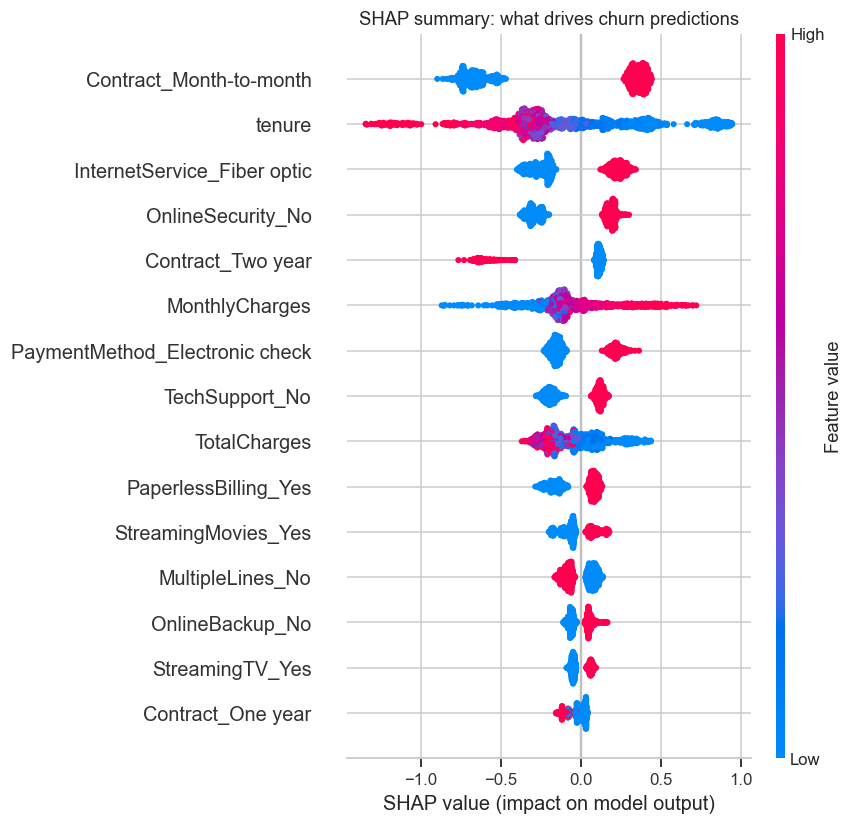

In [17]:
prep, clf = best.named_steps["prep"], best.named_steps["clf"]
Xt = prep.transform(X_test); Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
names = [n.split("__")[1] for n in prep.get_feature_names_out()]
Xt_df = pd.DataFrame(Xt, columns=names)

if "XGB" in best_name or "Forest" in best_name:
    sv = shap.TreeExplainer(clf).shap_values(Xt_df)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if getattr(sv, "ndim", 2) == 3 else sv)
else:
    sv = shap.LinearExplainer(clf, prep.transform(X_train)).shap_values(Xt_df)
shap.summary_plot(sv, Xt_df, max_display=15, show=False)
plt.title("SHAP summary: what drives churn predictions"); plt.savefig("images/09_shap_summary.png", bbox_inches="tight"); plt.show()

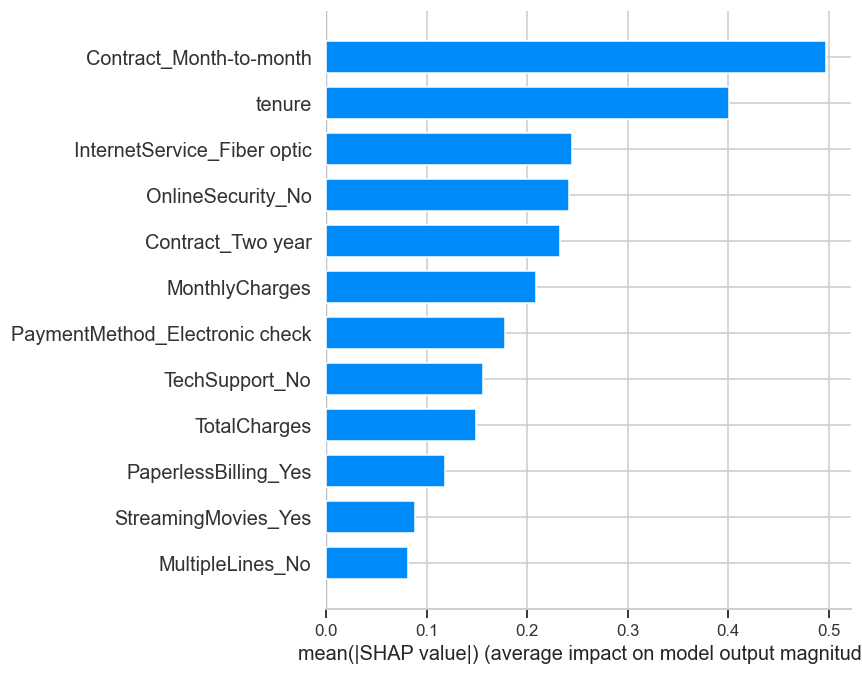

In [18]:
shap.summary_plot(sv, Xt_df, plot_type="bar", max_display=12, show=False)
plt.savefig("images/10_shap_importance.png", bbox_inches="tight"); plt.show()

## 8. Business recommendations

| Finding | Action |
|---|---|
| Month-to-month contracts drive most churn | Offer discounts or perks for upgrading to 1 or 2-year contracts, especially in months 1 to 6 |
| Churn peaks early in tenure | Build an onboarding programme with a check-in call or welcome offer in the first 90 days |
| Fiber optic customers churn more despite paying more | Investigate service quality and pricing for fiber; consider price-lock offers |
| Tech Support and Online Security customers stay | Bundle them free for a trial period for high-risk customers |
| Electronic check users churn more | Incentivise a switch to automatic payments (small bill credit) |
| Model gives each customer a churn probability | Rank customers weekly and target the top decile with retention offers using the cost-optimal threshold |

**Limitations:** the dataset is a single snapshot with no time dimension, the cost figures are assumptions, and the offer's effect on churn would need an A/B test to confirm.

## 9. Save the model

In [19]:
joblib.dump({"model": best, "threshold": float(best_t), "model_name": best_name,
             "num_cols": num_cols, "cat_cols": cat_cols}, "models/churn_model.joblib")
results.to_csv("models/results.csv")
print("Saved models/churn_model.joblib  (", best_name, ")")

Saved models/churn_model.joblib  ( XGBoost (tuned) )
